Load the CARTO API key from Colab Secrets so generated maps can use the authenticated basemap.


In [1]:
from google.colab import userdata
import os

os.environ["CARTO_API_KEY"] = userdata.get("CARTO_API_KEY")

Clone the project repository, enter its folder, and install the package in editable mode.


In [2]:
!git clone https://github.com/talalhaider9/LucidMA2.0.git
%cd LucidMA2.0
!pip install -q -e .

Cloning into 'LucidMA2.0'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 72 (delta 28), reused 56 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 494.04 KiB | 20.58 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/LucidMA2.0
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.4/113.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.8/98.8 kB 5.3 MB/s eta 0:00:00
  Building editable for lucid-ma (pyproject.toml) ... done


Run the standard analysis for theft from motor vehicles and save its reports and visualizations.


In [3]:
!python -m lucid_ma --query "theft from motor vehicle" --limit 50000

I0000 00:00:1792566328.014578    8395 pjrt_api.cc:119] GetPjrtApi was found for TPU at /usr/local/lib/python3.13/dist-packages/libtpu/libtpu.so
I0000 00:00:1792566328.846041    8395 device_rt.cc:166] PjRt runtime initialization deferred for tpu
Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
I0000 00:00:1792566328.859279    8395 libtpu_version.cc:63] Setting libtpu version to: 0.0.50
Analyzing query: theft from motor vehicle
Fetching Chicago crime data...
Cleaned data: 50,000 records
Knowledge graph: 70,108 nodes, 799,667 edges
modules.json: 100% 349/349 [00:00<00:00, 2.51MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 1.11MB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 44.8MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 526kB/s]
config.json: 100% 612/612 [00:00<00:00, 6.34MB/s]

model.safetensors: downloading b

Install the project?s optional dependencies for the multi-agent analysis workflow.


In [4]:
!pip install -q -e ".[agents]"

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 75.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.0/345.0 kB 31.7 MB/s eta 0:00:00
  Building editable for lucid-ma (pyproject.toml) ... done


Install the Ollama runtime in Colab and verify that its executable is available.


In [5]:
!apt-get update -qq
!apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh
!which ollama
!ollama --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package zstd.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
/usr/local/bin/ollama


Start the Ollama server in the background and check which language models are installed.


In [6]:
!nohup ollama serve > /tmp/ollama.log 2>&1 &
!sleep 8
!ollama list

NAME    ID    SIZE    MODIFIED 


Download the configured DeepSeek model that the optional agents will use.


In [7]:
!ollama pull deepseek-r1:8b

List the locally available Ollama models to confirm the model download.


In [8]:
!ollama list

NAME                ID              SIZE      MODIFIED      
deepseek-r1:1.5b    e0979632db5a    1.1 GB    4 seconds ago    


Install AG2, the AutoGen-compatible framework required by the agent workflow.


In [9]:
%pip install -q "ag2[openai]"

Start Ollama and wait for its local API to respond before running the agents.


In [10]:
import shutil
import subprocess
import time
import requests

ollama_path = shutil.which("ollama")
assert ollama_path, "Ollama installation failed or the executable is not on PATH"

ollama_log = open("/tmp/ollama.log", "w")
ollama_process = subprocess.Popen(
    [ollama_path, "serve"],
    stdout=ollama_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=2).ok:
            print("Ollama is ready")
            break
    except requests.RequestException:
        pass
    time.sleep(2)
else:
    raise RuntimeError("Ollama did not start; inspect /tmp/ollama.log")

Ollama is ready


Install the AutoGen package used by the notebook?s multi-agent workflow.


In [11]:
!pip install autogen

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 83.2 MB/s eta 0:00:00


Run the assault analysis with agents enabled, producing the project?s reports and charts.


In [12]:
%cd /content/LucidMA2.0
!python -m lucid_ma --query "assault" --limit 30000 --agents

/content/LucidMA2.0
I0000 00:00:1792566425.378028   10100 pjrt_api.cc:119] GetPjrtApi was found for TPU at /usr/local/lib/python3.13/dist-packages/libtpu/libtpu.so
I0000 00:00:1792566426.045329   10100 device_rt.cc:166] PjRt runtime initialization deferred for tpu
Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
I0000 00:00:1792566426.048115   10100 libtpu_version.cc:63] Setting libtpu version to: 0.0.50
Analyzing query: assault
Fetching Chicago crime data...
Cleaned data: 30,000 records
Knowledge graph: 45,480 nodes, 479,791 edges
Loading weights: 100% 103/103 [00:00<00:00, 8454.44it/s]
--- VERIFIED CHICAGO CRIME PROFILE ---
Crime type: ASSAULT
Records: 2979 (2972 have coordinate data)
Coverage: 2026-08-27T04:06:00+00:00 to 2026-10-12T00:00:00+00:00
Peak observed hour: 15:00
Arrest rate: 12.2% | Domestic-related rate: 26.7%
Top descriptions: SIM

Read and display the generated Markdown analysis report.


In [13]:
print(open("outputs/analysis.md", encoding="utf-8").read())

# Assault analysis

Query: `assault`

- Records analyzed: 2979
- Records with coordinates: 2972
- Coverage: 2026-08-27T04:06:00+00:00 to 2026-10-12T00:00:00+00:00
- Peak observed hour: 15:00
- Arrest rate: 12.2%
- Domestic-related rate: 26.7%

## Top descriptions

- SIMPLE: 1994
- AGGRAVATED - HANDGUN: 495
- AGGRAVATED - KNIFE / CUTTING INSTRUMENT: 232
- AGGRAVATED - OTHER DANGEROUS WEAPON: 138
- PROTECTED EMPLOYEE - HANDS, FISTS, FEET, NO / MINOR INJURY: 49
- AGGRAVATED POLICE OFFICER - HANDS, FISTS, FEET, NO INJURY: 31
- AGGRAVATED - OTHER FIREARM: 13
- AGGRAVATED PROTECTED EMPLOYEE - OTHER DANGEROUS WEAPON: 6
- AGGRAVATED POLICE OFFICER - HANDGUN: 5
- AGGRAVATED PROTECTED EMPLOYEE - HANDGUN: 5

## Top location types

- APARTMENT: 730
- STREET: 628
- RESIDENCE: 334
- SIDEWALK: 249
- RESTAURANT: 81
- ALLEY: 70
- SMALL RETAIL STORE: 67
- GAS STATION: 65
- PARKING LOT / GARAGE (NON RESIDENTIAL): 59
- SCHOOL - PUBLIC GROUNDS: 58

## Top community areas

- 25: 157
- 43: 120
- 71: 113
- 29

Fetch crime records, build the incident graph, and plot a readable summary of top assault attributes.


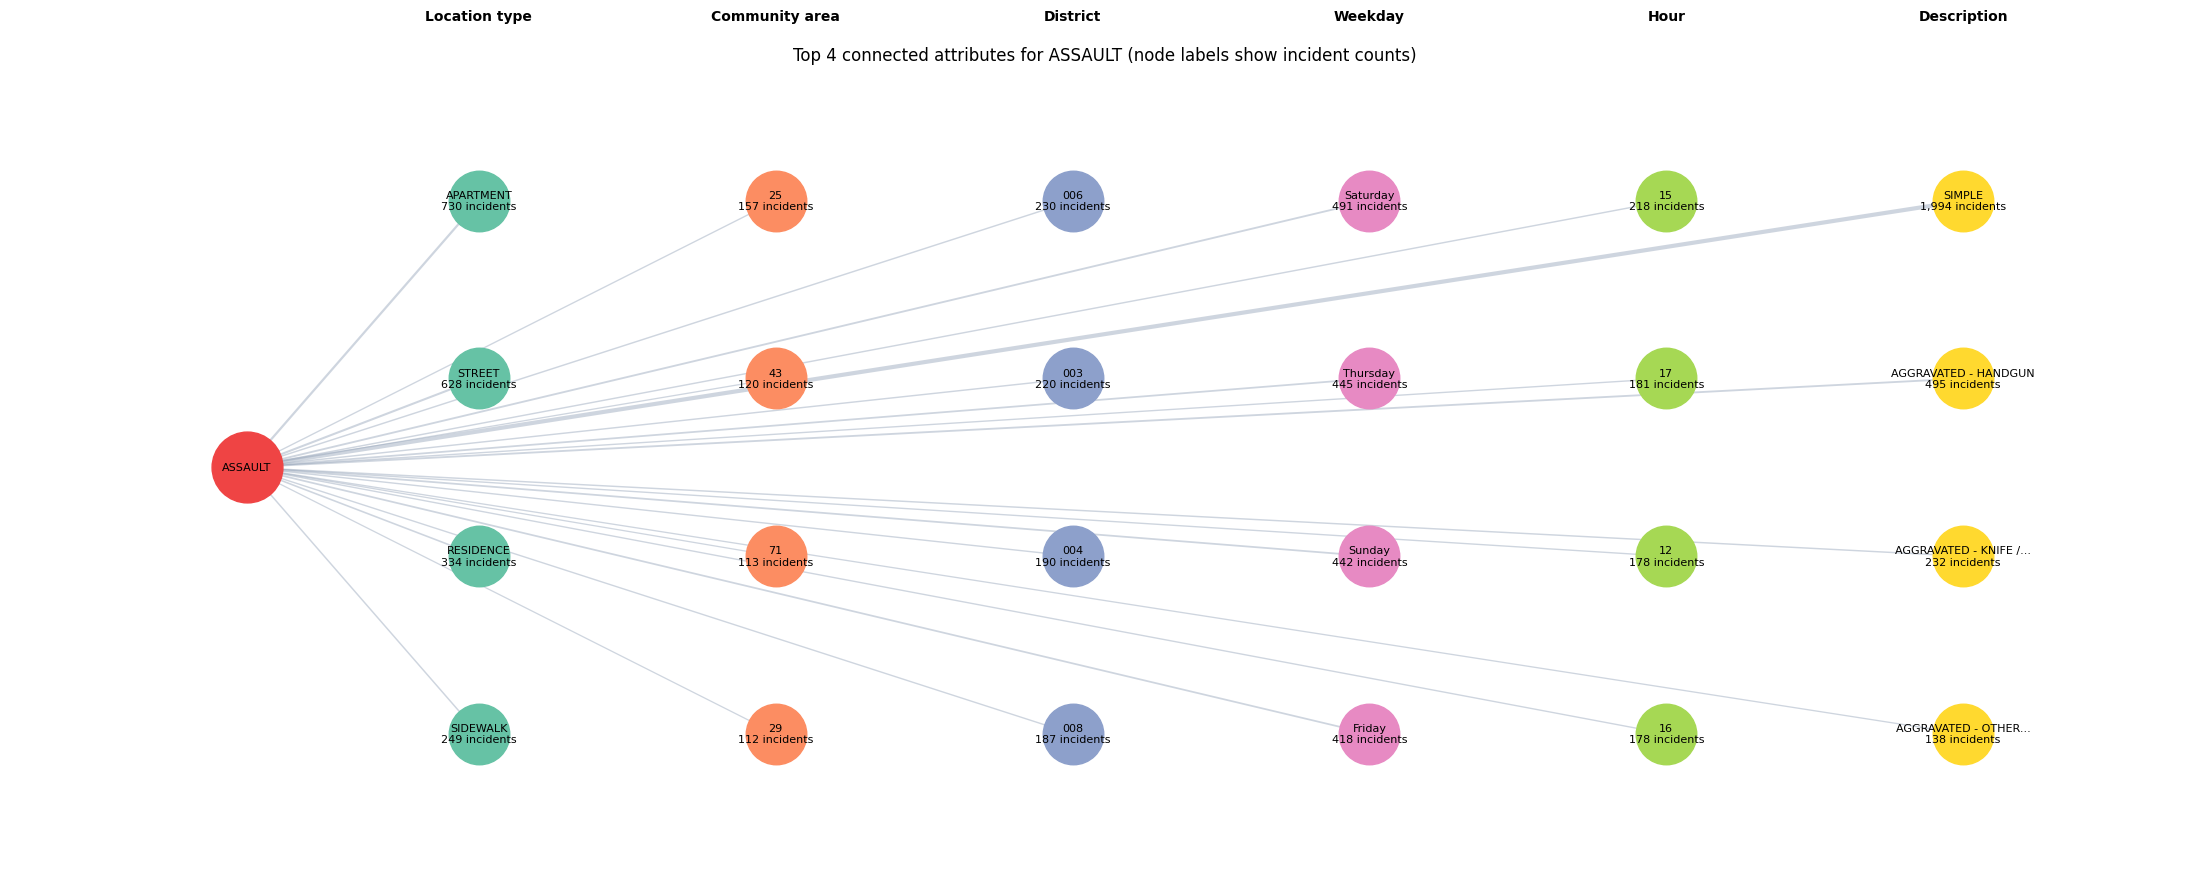

In [14]:
import sys
sys.path.insert(0, "/content/LucidMA2.0/src")

from collections import Counter
import textwrap

from lucid_ma.data import fetch_crime_data, build_crime_graph
import networkx as nx
import matplotlib.pyplot as plt

df = fetch_crime_data()
graph = build_crime_graph(df)

crime_type = "ASSAULT"
crime_node = f"crime:{crime_type}"

if crime_node not in graph:
    raise ValueError(f"No incidents found for crime type {crime_type!r}.")

# The crime node connects to incidents; each incident connects to its attributes.
incident_nodes = [
    node for node in graph.neighbors(crime_node)
    if graph.nodes[node].get("kind") == "incident"
]
attribute_counts = Counter()
for incident_node in incident_nodes:
    for attribute_node in graph.neighbors(incident_node):
        kind = graph.nodes[attribute_node].get("kind")
        label = graph.nodes[attribute_node].get("label")
        if kind and kind != "incident" and label is not None:
            attribute_counts[(kind, str(label))] += 1

dimensions = [
    ("location", "Location type"),
    ("community", "Community area"),
    ("district", "District"),
    ("weekday", "Weekday"),
    ("hour", "Hour"),
    ("description", "Description"),
]
top_n = 4
summary = nx.Graph()
summary.add_node(crime_node, kind="crime", label=crime_type)
groups = []
for kind, title in dimensions:
    values = sorted(
        ((label, count) for (value_kind, label), count in attribute_counts.items() if value_kind == kind),
        key=lambda item: (-item[1], item[0]),
    )[:top_n]
    if values:
        groups.append((kind, title, values))
        for value, count in values:
            node = f"attribute:{kind}:{value}"
            summary.add_node(node, kind=kind, label=value, count=count)
            summary.add_edge(crime_node, node, weight=count)

if not groups:
    raise ValueError(f"No connected attributes found for crime type {crime_type!r}.")

# Fixed columns by attribute type keep the plot readable and comparable.
positions = {crime_node: (-2.5, 0)}
for column, (_, _, values) in enumerate(groups):
    for row, (value, _) in enumerate(values):
        node = f"attribute:{groups[column][0]}:{value}"
        positions[node] = (column * 3.2, (len(values) - 1) / 2 - row)

labels = {crime_node: crime_type}
for node, data in summary.nodes(data=True):
    if node != crime_node:
        value = textwrap.shorten(data["label"], width=26, placeholder="...")
        labels[node] = f"{value}\n{data['count']:,} incidents"

max_count = max(data["weight"] for _, _, data in summary.edges(data=True))
edge_widths = [0.8 + 2.2 * data["weight"] / max_count for _, _, data in summary.edges(data=True)]
figure, axis = plt.subplots(figsize=(max(16, 3.2 * len(groups) + 3), max(7, 2.2 * top_n)))
nx.draw_networkx_edges(
    summary, positions, ax=axis, width=edge_widths, edge_color="#94a3b8", alpha=0.45
)
nx.draw_networkx_nodes(
    summary, positions, nodelist=[crime_node], node_color="#ef4444", node_size=2600, ax=axis
)
palette = plt.get_cmap("Set2")
for index, (kind, title, _) in enumerate(groups):
    nodes = [node for node, data in summary.nodes(data=True) if data.get("kind") == kind]
    nx.draw_networkx_nodes(
        summary, positions, nodelist=nodes, node_color=[palette(index % 8)], node_size=1900, ax=axis
    )
    axis.text(index * 3.2, top_n / 2 + 0.5, title, ha="center", va="bottom", fontsize=10, fontweight="bold")

nx.draw_networkx_labels(summary, positions, labels=labels, font_size=8, ax=axis)
axis.set_title(f"Top {top_n} connected attributes for {crime_type} (node labels show incident counts)")
axis.margins(x=0.08, y=0.18)
axis.axis("off")
figure.tight_layout()
plt.show()

Zip the project folder and download the archive to the local computer.


In [15]:
!zip -r /content/downloaded_folder.zip /content/LucidMA2.0/

# 2. Download the zip file to your local computer
from google.colab import files
files.download("/content/downloaded_folder.zip")

  adding: content/LucidMA2.0/ (stored 0%)
  adding: content/LucidMA2.0/pyproject.toml (deflated 43%)
  adding: content/LucidMA2.0/README.md (deflated 53%)
  adding: content/LucidMA2.0/requirements.txt (stored 0%)
  adding: content/LucidMA2.0/outputs/ (stored 0%)
  adding: content/LucidMA2.0/outputs/analysis.json (deflated 79%)
  adding: content/LucidMA2.0/outputs/location_types.png (deflated 22%)
  adding: content/LucidMA2.0/outputs/hourly_incidents.png (deflated 22%)
  adding: content/LucidMA2.0/outputs/districts.png (deflated 29%)
  adding: content/LucidMA2.0/outputs/crime_hotspots.html (deflated 79%)
  adding: content/LucidMA2.0/outputs/analysis.md (deflated 49%)
  adding: content/LucidMA2.0/outputs/.gitkeep (stored 0%)
  adding: content/LucidMA2.0/outputs/community_areas.png (deflated 25%)
  adding: content/LucidMA2.0/outputs/descriptions.png (deflated 18%)
  adding: content/LucidMA2.0/.git/ (stored 0%)
  adding: content/LucidMA2.0/.git/hooks/ (stored 0%)
  adding: content/LucidMA2

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>